In [65]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier

train_df = pd.read_csv("../data/train_features.csv")
test_df = pd.read_csv("../data/test_features.csv")

X_train = train_df.drop(columns=["Class"])
y_train = train_df["Class"]

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Training Complete!")

Training Complete!


Accuracy: 0.992503748125937


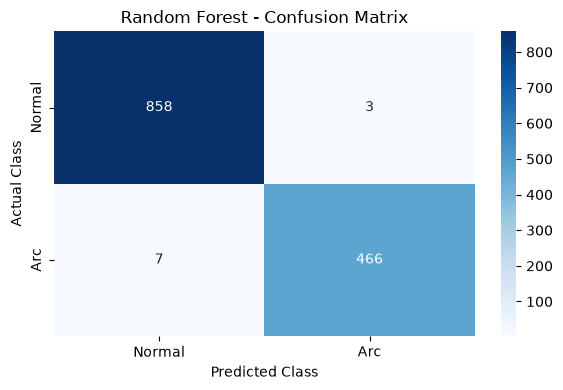


Classification Report:
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99       861
         Arc       0.99      0.99      0.99       473

    accuracy                           0.99      1334
   macro avg       0.99      0.99      0.99      1334
weighted avg       0.99      0.99      0.99      1334



In [66]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Separate test features and true labels
X_test = test_df.drop(columns=["Class"])
y_test = test_df["Class"]

# Predict the classes
y_test_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_test_pred))

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(6, 4))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Arc"],
    yticklabels=["Normal", "Arc"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")

plt.tight_layout()
plt.show()

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred,
    target_names=["Normal", "Arc"]
))

In [67]:
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train)

print("Training accuracy: ", accuracy_score(y_train, y_train_pred))

print("Testing accuracy: ", accuracy_score(y_test, y_test_pred))


Training accuracy:  1.0
Testing accuracy:  0.992503748125937


In [68]:

import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

results = []

for depth in [None, 10, 5, 3]:
    rf = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_train, y_train)
    predictions = rf.predict(X_test)

    # Confusion matrix order: Normal (0), Arc (1)
    tn, fp, fn, tp = confusion_matrix(
        y_test, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Max Depth": str(depth),
        "Accuracy": accuracy_score(y_test, predictions),
        "Arc Precision": precision_score(
            y_test, predictions, pos_label=1
        ),
        "Arc Recall": recall_score(
            y_test, predictions, pos_label=1
        ),
        "Arc F1": f1_score(
            y_test, predictions, pos_label=1
        ),
        "Missed Arcs": fn,
        "False Alarms": fp
    })

results_df = pd.DataFrame(results)

print(results_df.round(4).to_string(index=False))


Max Depth  Accuracy  Arc Precision  Arc Recall  Arc F1  Missed Arcs  False Alarms
     None    0.9925         0.9936      0.9852  0.9894            7             3
       10    0.9895         0.9914      0.9789  0.9851           10             4
        5    0.9670         0.9886      0.9175  0.9518           39             5
        3    0.9535         0.9768      0.8901  0.9314           52            10


              Feature  Importance
High_Frequency_Energy    0.229315
             Kurtosis    0.176916
    Spectral_Centroid    0.164054
         Crest_Factor    0.090663
             Skewness    0.072140
                 Mean    0.059217
           FFT_Energy    0.049250
             variance    0.037454
         peak_to_peak    0.036119
                  RMS    0.035285
                 peak    0.034861
   Dominant_Frequency    0.014727


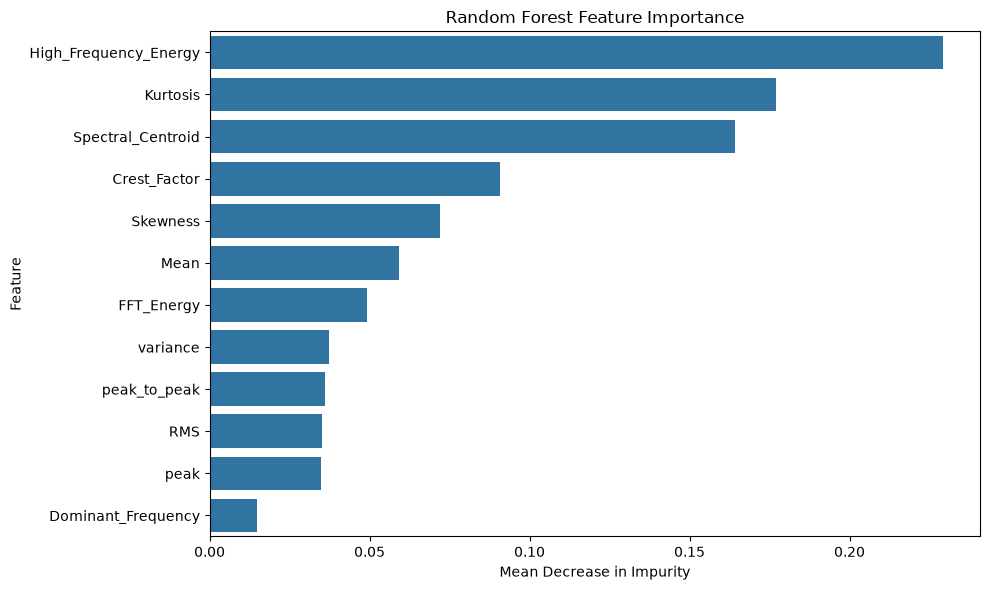

In [69]:

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": model.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

print(importance_df.to_string(index=False))

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance_df,
    x="Importance",
    y="Feature"
)

plt.title("Random Forest Feature Importance")
plt.xlabel("Mean Decrease in Impurity")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


              Feature  Importance      Std
High_Frequency_Energy    0.088298 0.026934
             Kurtosis    0.037234 0.005319
                 Mean    0.000000 0.000000
                  RMS    0.000000 0.000000
           FFT_Energy    0.000000 0.000000
                 peak    0.000000 0.000000
   Dominant_Frequency    0.000000 0.000000
         peak_to_peak   -0.001064 0.003191
    Spectral_Centroid   -0.002128 0.014113
             Skewness   -0.002128 0.006383
             variance   -0.002128 0.004255
         Crest_Factor   -0.006383 0.005212


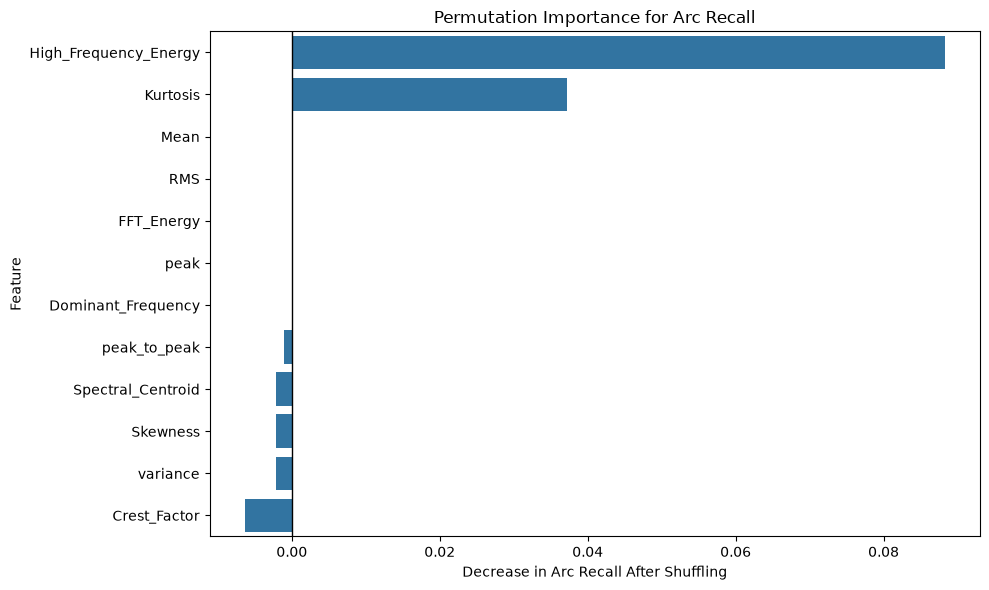

In [70]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

# validation split from the training data
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Fit a fresh model on the fitting subset
validation_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

validation_model.fit(X_fit, y_fit)

# Measure permutation importance on validation data
perm = permutation_importance(
    validation_model,
    X_val,
    y_val,
    scoring="recall",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

# Convert the results into a DataFrame
perm_df = pd.DataFrame({
    "Feature": X_val.columns,
    "Importance": perm.importances_mean,
    "Std": perm.importances_std
}).sort_values("Importance", ascending=False)


print(perm_df.to_string(index=False))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=perm_df,
    x="Importance",
    y="Feature"
)
plt.axvline(0, color="black", linewidth=1)
plt.title("Permutation Importance for Arc Recall")
plt.xlabel("Decrease in Arc Recall After Shuffling")
plt.tight_layout()
plt.show()


In [71]:
feature_sets = {
    "All 12 features": X_fit.columns.tolist(),
    "Top 2 features": [
        "High_Frequency_Energy",
        "Kurtosis"
    ],

    "Top 5 features": [
        "High_Frequency_Energy",
        "Kurtosis",
        "Spectral_Centroid",
        "Crest_Factor",
        "Skewness",
    ]
}

results = []

for name, features in feature_sets.items():
    rf = RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )

    rf.fit(X_fit[features], y_fit)
    predictions = rf.predict(X_val[features])

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Feature Set": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Arc Recall": recall_score(y_val, predictions),
        "Arc Precision": precision_score(y_val, predictions),
        "Arc F1": f1_score(y_val, predictions),
        "Missed Arcs": fn,
        "False Alarms": fp
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

    Feature Set  Accuracy  Arc Recall  Arc Precision  Arc F1  Missed Arcs  False Alarms
All 12 features    0.9813      0.9574         0.9890  0.9730            4             1
 Top 2 features    0.9551      0.9149         0.9556  0.9348            8             4
 Top 5 features    0.9775      0.9468         0.9889  0.9674            5             1


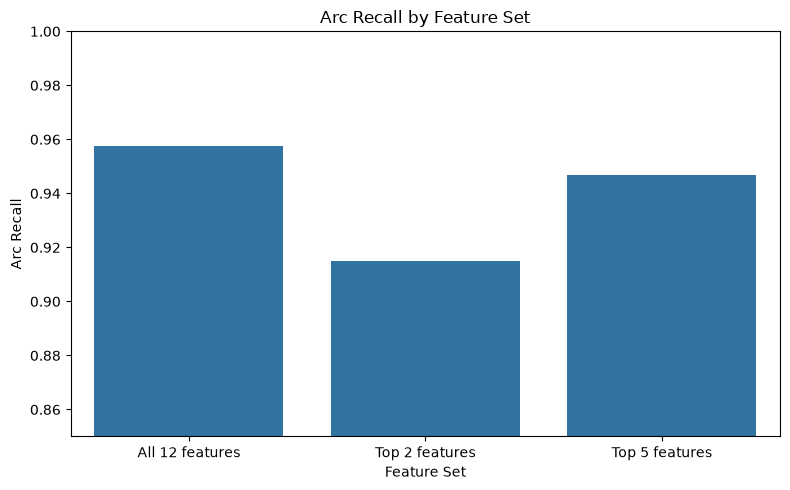

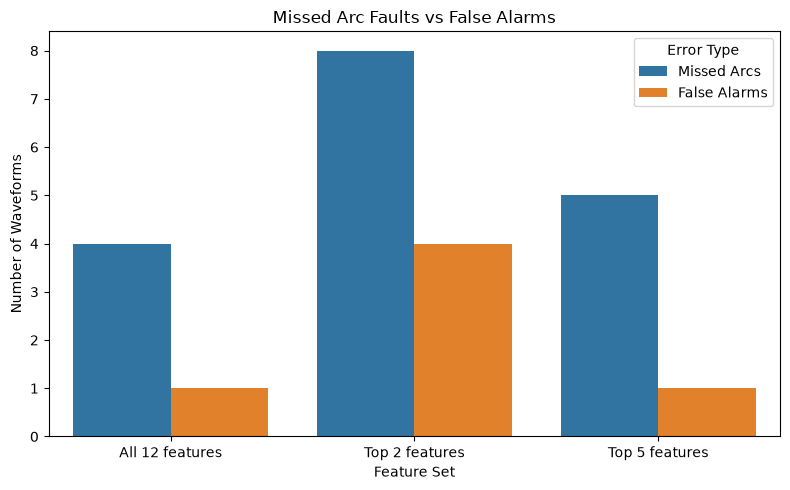

In [72]:
import seaborn as sns
import matplotlib.pyplot as plt

# Plot 1: Arc recall
plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Feature Set",
    y="Arc Recall"
)

plt.title("Arc Recall by Feature Set")
plt.ylabel("Arc Recall")
plt.ylim(0.85, 1.0)

plt.tight_layout()
plt.show()


# Plot 2: Missed arcs vs false alarms
error_df = results_df.melt(
    id_vars="Feature Set",
    value_vars=["Missed Arcs", "False Alarms"],
    var_name="Error Type",
    value_name="Count"
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=error_df,
    x="Feature Set",
    y="Count",
    hue="Error Type"
)

plt.title("Missed Arc Faults vs False Alarms")
plt.ylabel("Number of Waveforms")

plt.tight_layout()
plt.show()

In [73]:

import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score

# Probability assigned to the Arc class (class 1)
arc_index = list(validation_model.classes_).index(1)
arc_probabilities = validation_model.predict_proba(X_val)[:, arc_index]

results = []

for threshold in [0.5, 0.45, 0.4, 0.35, 0.3, 0.25]:
    predictions = (arc_probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predictions, labels=[0, 1]
    ).ravel()

    results.append({
        "Threshold": threshold,
        "Accuracy": accuracy_score(y_val, predictions),
        "Arc Recall": recall_score(y_val, predictions),
        "Arc Precision": precision_score(
            y_val, predictions, zero_division=0
        ),
        "Missed Arcs": fn,
        "False Alarms": fp
    })

threshold_df = pd.DataFrame(results)
print(threshold_df.round(4).to_string(index=False))


 Threshold  Accuracy  Arc Recall  Arc Precision  Missed Arcs  False Alarms
      0.50    0.9813      0.9574         0.9890            4             1
      0.45    0.9850      0.9681         0.9891            3             1
      0.40    0.9850      0.9681         0.9891            3             1
      0.35    0.9850      0.9681         0.9891            3             1
      0.30    0.9850      0.9787         0.9787            2             2
      0.25    0.9850      0.9894         0.9688            1             3


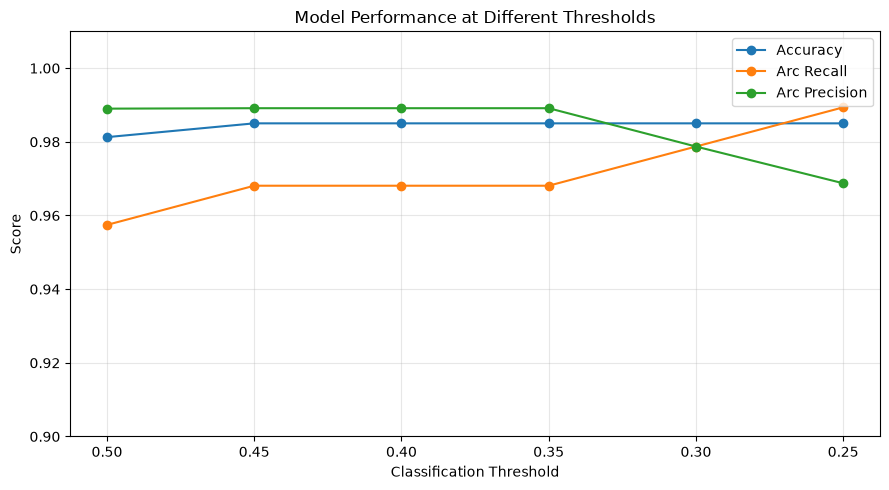

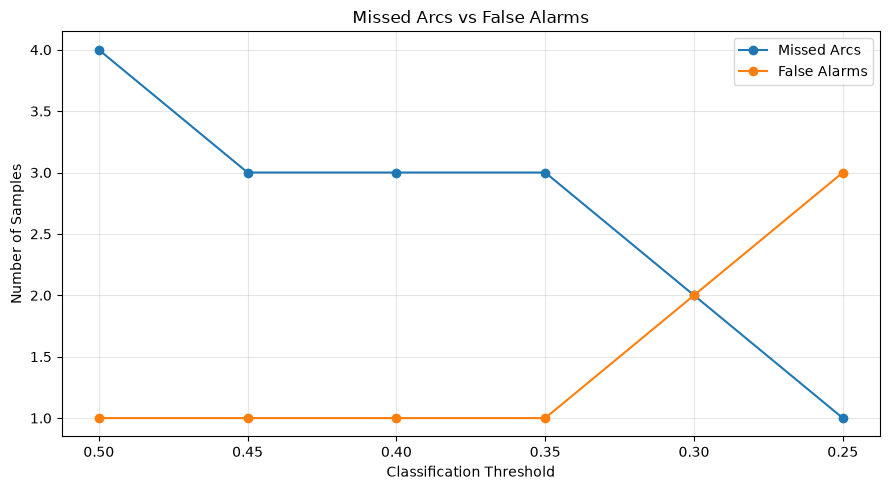

In [74]:
import matplotlib.pyplot as plt

# Plot 1: Accuracy, Arc Recall and Arc Precision
plt.figure(figsize=(9, 5))

plt.plot(threshold_df["Threshold"], threshold_df["Accuracy"],
         marker="o", label="Accuracy")
plt.plot(threshold_df["Threshold"], threshold_df["Arc Recall"],
         marker="o", label="Arc Recall")
plt.plot(threshold_df["Threshold"], threshold_df["Arc Precision"],
         marker="o", label="Arc Precision")

plt.xlabel("Classification Threshold")
plt.ylabel("Score")
plt.title("Model Performance at Different Thresholds")
plt.xticks(threshold_df["Threshold"])
plt.ylim(0.90, 1.01)
plt.grid(True, alpha=0.3)
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()


# Plot 2: Missed Arcs vs False Alarms
plt.figure(figsize=(9, 5))

plt.plot(threshold_df["Threshold"], threshold_df["Missed Arcs"],
         marker="o", label="Missed Arcs")
plt.plot(threshold_df["Threshold"], threshold_df["False Alarms"],
         marker="o", label="False Alarms")

plt.xlabel("Classification Threshold")
plt.ylabel("Number of Samples")
plt.title("Missed Arcs vs False Alarms")
plt.xticks(threshold_df["Threshold"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.gca().invert_xaxis()
plt.tight_layout()
plt.show()

Selected threshold: 0.3
 Threshold  Accuracy  Arc Recall  Arc Precision  Missed Arcs  False Alarms
       0.3     0.985      0.9787         0.9787            2             2


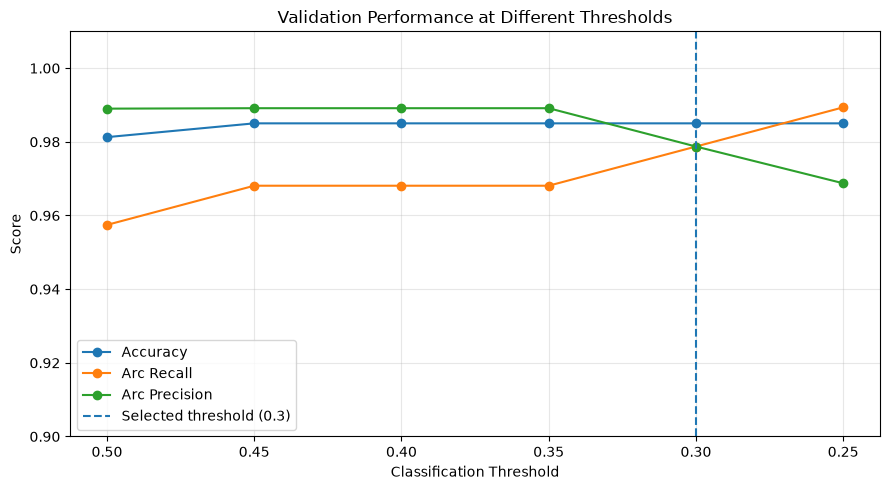

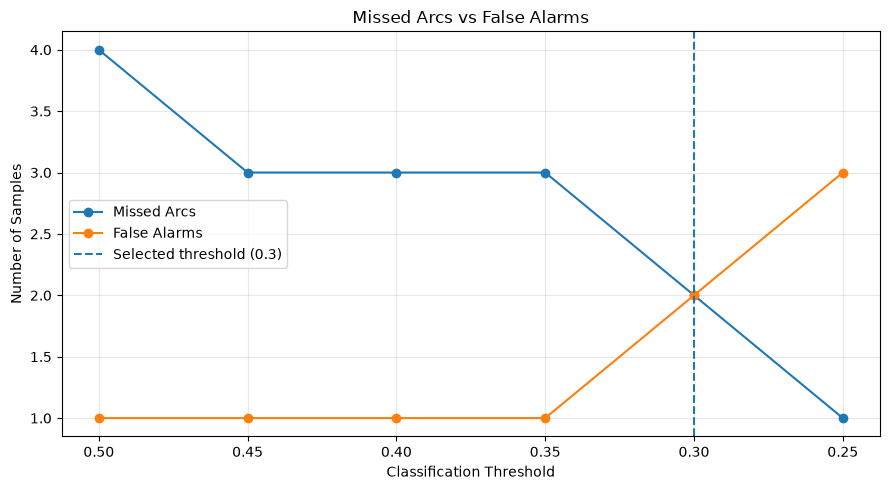


Saved files:
..\data\threshold_comparison.csv
..\data\threshold_performance.png
..\data\threshold_tradeoff.png


In [75]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Selected candidate threshold
BEST_THRESHOLD = 0.30

# Save threshold comparison results
DATA_DIR = Path("../data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

threshold_df.to_csv(DATA_DIR / "threshold_comparison.csv", index=False)

# Display selected threshold results
selected_result = threshold_df[
    threshold_df["Threshold"] == BEST_THRESHOLD
]

print("Selected threshold:", BEST_THRESHOLD)
print(selected_result.round(4).to_string(index=False))


# Plot 1: Performance metrics
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(threshold_df["Threshold"], threshold_df["Accuracy"],
        marker="o", label="Accuracy")
ax.plot(threshold_df["Threshold"], threshold_df["Arc Recall"],
        marker="o", label="Arc Recall")
ax.plot(threshold_df["Threshold"], threshold_df["Arc Precision"],
        marker="o", label="Arc Precision")

ax.axvline(BEST_THRESHOLD, linestyle="--",
           label=f"Selected threshold ({BEST_THRESHOLD})")

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Score")
ax.set_title("Validation Performance at Different Thresholds")
ax.set_xticks(threshold_df["Threshold"])
ax.set_ylim(0.90, 1.01)
ax.grid(True, alpha=0.3)
ax.legend()
ax.invert_xaxis()

fig.tight_layout()
fig.savefig(DATA_DIR / "threshold_performance.png", dpi=300)
plt.show()


# Plot 2: Missed arcs vs false alarms
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(threshold_df["Threshold"], threshold_df["Missed Arcs"],
        marker="o", label="Missed Arcs")
ax.plot(threshold_df["Threshold"], threshold_df["False Alarms"],
        marker="o", label="False Alarms")

ax.axvline(BEST_THRESHOLD, linestyle="--",
           label=f"Selected threshold ({BEST_THRESHOLD})")

ax.set_xlabel("Classification Threshold")
ax.set_ylabel("Number of Samples")
ax.set_title("Missed Arcs vs False Alarms")
ax.set_xticks(threshold_df["Threshold"])
ax.grid(True, alpha=0.3)
ax.legend()
ax.invert_xaxis()

fig.tight_layout()
fig.savefig(DATA_DIR / "threshold_tradeoff.png", dpi=300)
plt.show()

print("\nSaved files:")
print(DATA_DIR / "threshold_comparison.csv")
print(DATA_DIR / "threshold_performance.png")
print(DATA_DIR / "threshold_tradeoff.png")

In [76]:
import joblib
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier

DATA_DIR = Path("../data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Use all features, preserving their original order
selected_features = X_train.columns.tolist()

# Train the final candidate model on all training data
final_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

final_model.fit(X_train[selected_features], y_train)

# Save model and prediction configuration together
model_bundle = {
    "model": final_model,
    "features": selected_features,
    "threshold": 0.30,
    "class_labels": {
        0: "Normal",
        1: "Arc"
    }
}

model_path = DATA_DIR / "arc_fault_model.joblib"
joblib.dump(model_bundle, model_path)

print(f"Model saved to: {model_path}")
print(f"Number of features: {len(selected_features)}")
print(f"Threshold: {model_bundle['threshold']}")

Model saved to: ..\data\arc_fault_model.joblib
Number of features: 12
Threshold: 0.3
